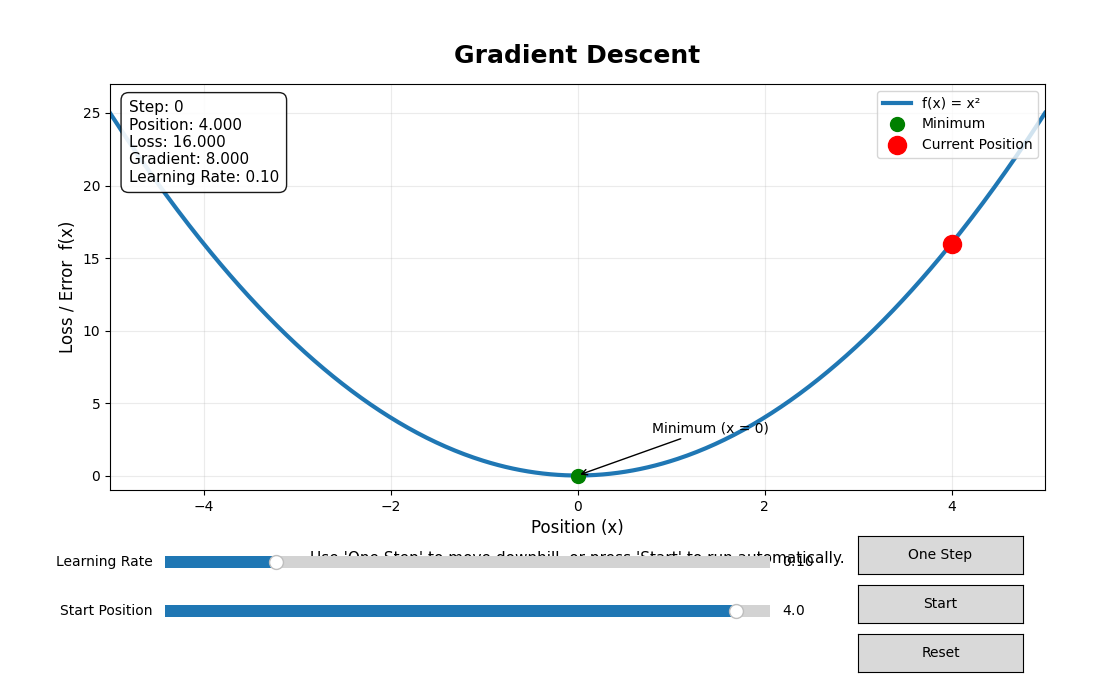

In [4]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.animation import FuncAnimation


# ============================================================
# 1. Function and Gradient
# ============================================================

def f(x):
    return x**2


def gradient(x):
    return 2 * x


# ============================================================
# 2. State
# ============================================================

state = {
    "x": 4.0,
    "step": 0,
    "running": False
}


# ============================================================
# 3. Figure
# ============================================================

fig, ax = plt.subplots(figsize=(11, 7))

plt.subplots_adjust(
    left=0.10,
    right=0.95,
    top=0.88,
    bottom=0.30
)


# ============================================================
# 4. Plot the Function
# ============================================================

x_values = np.linspace(-5, 5, 500)

ax.plot(
    x_values,
    f(x_values),
    linewidth=3,
    label="f(x) = x²"
)


# Minimum
ax.plot(
    0,
    0,
    "go",
    markersize=10,
    label="Minimum"
)

ax.annotate(
    "Minimum (x = 0)",
    xy=(0, 0),
    xytext=(0.8, 3),
    arrowprops=dict(arrowstyle="->"),
    fontsize=10
)


# ============================================================
# 5. Hiker / Current Position
# ============================================================

point, = ax.plot(
    state["x"],
    f(state["x"]),
    "ro",
    markersize=13,
    label="Current Position"
)


# ============================================================
# 6. Trail
# ============================================================

trail_x = [state["x"]]
trail_y = [f(state["x"])]

trail, = ax.plot(
    trail_x,
    trail_y,
    "b--",
    alpha=0.6,
    linewidth=1.5
)


# ============================================================
# 7. Information Box
# ============================================================

info = ax.text(
    0.02,
    0.96,
    "",
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=11,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        alpha=0.9
    )
)


# ============================================================
# 8. Explanation Text
# ============================================================

explanation = ax.text(
    0.5,
    -0.18,
    "",
    transform=ax.transAxes,
    ha="center",
    fontsize=11
)


# ============================================================
# 9. Graph Labels
# ============================================================

ax.set_title(
    "Gradient Descent",
    fontsize=18,
    fontweight="bold",
    pad=15
)

ax.set_xlabel(
    "Position (x)",
    fontsize=12
)

ax.set_ylabel(
    "Loss / Error  f(x)",
    fontsize=12
)

ax.set_xlim(-5, 5)
ax.set_ylim(-1, 27)

ax.grid(
    True,
    alpha=0.25
)

ax.legend(
    loc="upper right"
)


# ============================================================
# 10. Learning Rate Slider
# ============================================================

ax_lr = plt.axes([
    0.15,
    0.18,
    0.55,
    0.035
])

learning_rate = Slider(
    ax_lr,
    "Learning Rate",
    0.01,
    0.5,
    valinit=0.1,
    valstep=0.01
)


# ============================================================
# 11. Starting Position Slider
# ============================================================

ax_start = plt.axes([
    0.15,
    0.11,
    0.55,
    0.035
])

start_position = Slider(
    ax_start,
    "Start Position",
    -4.5,
    4.5,
    valinit=4.0,
    valstep=0.1
)


# ============================================================
# 12. Buttons
# ============================================================

ax_step = plt.axes([
    0.78,
    0.18,
    0.15,
    0.055
])

step_button = Button(
    ax_step,
    "One Step"
)


ax_start_button = plt.axes([
    0.78,
    0.11,
    0.15,
    0.055
])

start_button = Button(
    ax_start_button,
    "Start"
)


ax_reset = plt.axes([
    0.78,
    0.04,
    0.15,
    0.055
])

reset_button = Button(
    ax_reset,
    "Reset"
)


# ============================================================
# 13. Update Screen
# ============================================================

def update_screen(message=""):

    x = state["x"]

    y = f(x)

    slope = gradient(x)

    point.set_data([x], [y])

    trail.set_data(
        trail_x,
        trail_y
    )

    info.set_text(
        f"Step: {state['step']}\n"
        f"Position: {x:.3f}\n"
        f"Loss: {y:.3f}\n"
        f"Gradient: {slope:.3f}\n"
        f"Learning Rate: {learning_rate.val:.2f}"
    )

    explanation.set_text(message)

    fig.canvas.draw_idle()


# ============================================================
# 14. Gradient Descent Step
# ============================================================

def take_step():

    x_old = state["x"]

    slope = gradient(x_old)

    lr = learning_rate.val

    # Gradient Descent Formula
    x_new = x_old - lr * slope

    state["x"] = x_new

    state["step"] += 1

    trail_x.append(x_new)
    trail_y.append(f(x_new))

    message = (
        f"Gradient Descent Update:\n"
        f"x_new = x_old - learning_rate × gradient\n"
        f"x_new = {x_old:.2f} - {lr:.2f} × {slope:.2f}"
        f" = {x_new:.2f}"
    )

    update_screen(message)


# ============================================================
# 15. One Step Button
# ============================================================

def one_step(event):

    state["running"] = False

    start_button.label.set_text("Start")

    take_step()


step_button.on_clicked(one_step)


# ============================================================
# 16. Reset
# ============================================================

def reset(event=None):

    state["x"] = start_position.val

    state["step"] = 0

    state["running"] = False

    trail_x.clear()
    trail_y.clear()

    trail_x.append(state["x"])
    trail_y.append(f(state["x"]))

    start_button.label.set_text("Start")

    update_screen(
        "Use 'One Step' to move downhill, or press 'Start' to run automatically."
    )


reset_button.on_clicked(reset)


# ============================================================
# 17. Starting Position Slider
# ============================================================

def change_start(value):

    reset()


start_position.on_changed(change_start)


# ============================================================
# 18. Start / Pause
# ============================================================

def toggle_start(event):

    state["running"] = not state["running"]

    if state["running"]:

        start_button.label.set_text("Pause")

    else:

        start_button.label.set_text("Start")


start_button.on_clicked(toggle_start)


# ============================================================
# 19. Animation
# ============================================================

def animate(frame):

    if state["running"]:

        take_step()

        if abs(state["x"]) < 0.01:

            state["running"] = False

            start_button.label.set_text("Start")

            update_screen(
                "Reached the minimum!"
            )


animation = FuncAnimation(
    fig,
    animate,
    interval=500,
    cache_frame_data=False
)


# ============================================================
# 20. Click on Graph
# ============================================================

def mouse_click(event):

    if event.inaxes == ax and event.xdata is not None:

        state["x"] = np.clip(
            event.xdata,
            -4.5,
            4.5
        )

        state["step"] = 0

        state["running"] = False

        start_button.label.set_text("Start")

        trail_x.clear()
        trail_y.clear()

        trail_x.append(state["x"])
        trail_y.append(f(state["x"]))

        update_screen(
            "New starting position selected. Press 'One Step' to continue."
        )


fig.canvas.mpl_connect(
    "button_press_event",
    mouse_click
)


# ============================================================
# 21. Start
# ============================================================

reset()

plt.show()
